# Dataset, baselines and LSTM
Combine prices, Kalshi and news into one table, builds 20-day windows, and compares baseline with an LSTM.

- **Split by time:** train 2022–2024, validation 2025, test Jan–Sep 2026. Features are standardized with training-set statistics only.
- **Example:** the previous 20 trading days of features → label = 1 if the next day's close is higher.
- **Feature groups:** price (3), news (2), Kalshi (4). The four LSTM versions use price, price + news, price + Kalshi, and all three.

Run `prices.ipynb`, `kalshi.ipynb` and `news.ipynb` first

In [99]:
# import dependencies
import copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

## Load and combine datasets

In [100]:
prices = pd.read_csv("data/prices.csv", index_col=0, parse_dates=True)
kalshi = pd.read_csv("data/kalshi.csv", index_col=0, parse_dates=True)
news = pd.read_csv("data/news.csv", index_col=0, parse_dates=True)
df = prices.join(kalshi).join(news)      # line up rows by date

PRICE = ["log_return", "hl_range", "log_volume_change"]
NEWS = ["news_score", "news_count"]
KALSHI = ["p_hike", "p_cut", "d_hike", "d_cut"]
ALL = PRICE + NEWS + KALSHI

print(df.shape)
print("Missing values:", int(df[ALL + ["label"]].isna().sum().sum()))
print("Infinite values:", int(np.isinf(df[ALL + ["label"]]).sum().sum()))

(1190, 12)
Missing values: 0
Infinite values: 0


## Split dataset by time and standardize
Mean and SD come from training days only (only up to end of 2024).

In [101]:
train_mask = df.index < "2025-01-01"
val_mask = (df.index >= "2025-01-01") & (df.index < "2026-01-01")
test_mask = df.index >= "2026-01-01"
print("Train days:", train_mask.sum(), " Val days:", val_mask.sum(), " Test days:", test_mask.sum())

mean = df.loc[train_mask, ALL].mean()
std = df.loc[train_mask, ALL].std()

X_all = ((df[ALL] - mean) / std).astype(np.float32)   # standardized features, every day
y_all = df["label"].values.astype(np.float32)

Train days: 753  Val days: 250  Test days: 187


## Build 20-day windows
A window belongs to the set of its last day. Early validation and test windows include some days from the previous set, which uses only past features and never a future label.

In [102]:
WINDOW = 20

def make_windows(cols, mask):
    # Windows ending on days in `mask`, using feature columns `cols`
    X_feat = X_all[cols].values           
    Xs, ys = [], []
    for t in range(WINDOW - 1, len(df)):  # need 19 days before first window
        if mask[t]:
            Xs.append(X_feat[t - WINDOW + 1 : t + 1])   # rows t-19 to t
            ys.append(y_all[t])
    return np.stack(Xs), np.array(ys)

X_tr, y_tr = make_windows(PRICE, train_mask)
X_va, y_va = make_windows(PRICE, val_mask)
X_te, y_te = make_windows(PRICE, test_mask)
print(X_tr.shape, X_va.shape, X_te.shape)       # training (734 days), validation (250 days), test (187 days) windows
print("Up-day share: train", y_tr.mean().round(3), " val", y_va.mean().round(3), " test", y_te.mean().round(3))

(734, 20, 3) (250, 20, 3) (187, 20, 3)
Up-day share: train 0.519  val 0.58  test 0.513


## Baseline
1. **Majority class:** always predict the direction most common in training ("up").
2. **Logistic regression:** the 20-day price window flattened into one vector (60 numbers). The L2 strength C is chosen on validation.

In [ ]:
# Majority class: always predict the direction most common in TRAINING
majority = 1.0 if y_tr.mean() >= 0.5 else 0.0
print("Majority class predicts:", "up" if majority == 1 else "down")
print("Majority val acc: ", accuracy_score(y_va, np.full_like(y_va, majority)))
print("Majority test acc:", accuracy_score(y_te, np.full_like(y_te, majority)), "\n")

# Logistic regression on the 20-day window flattened into one vector
Xtr_flat = X_tr.reshape(len(X_tr), -1)     # (734, 20*3 = 60)
Xva_flat = X_va.reshape(len(X_va), -1)
Xte_flat = X_te.reshape(len(X_te), -1)

best_C, best_acc = None, -1
for C in [0.001, 0.01, 0.1, 1, 10]:        # L2 strength, tuned on VALIDATION
    logreg = LogisticRegression(C=C, max_iter=2000).fit(Xtr_flat, y_tr)
    acc = accuracy_score(y_va, logreg.predict(Xva_flat))
    print(f"C={C}: val acc {acc:.3f}")
    if acc > best_acc:
        best_C, best_acc = C, acc

logreg = LogisticRegression(C=best_C, max_iter=2000).fit(Xtr_flat, y_tr)
print("\nBest C:", best_C)
print("LogReg val acc: ", accuracy_score(y_va, logreg.predict(Xva_flat)))
print("LogReg test acc:", accuracy_score(y_te, logreg.predict(Xte_flat)))

Majority class predicts: up
Majority val acc:  0.58
Majority test acc: 0.5133689839572193 

C=0.001: val acc 0.560
C=0.01: val acc 0.536
C=0.1: val acc 0.512
C=1: val acc 0.484
C=10: val acc 0.480

Best C: 0.001
LogReg val acc:  0.56
LogReg test acc: 0.47058823529411764


In [104]:
flat = lambda X: X.reshape(len(X), -1)          # (n, 20, d) -> (n, 20*d)

# price-only baseline, refit with the best C
logreg = LogisticRegression(C=best_C, max_iter=2000).fit(flat(X_tr), y_tr)
pred_va, pred_te = logreg.predict(flat(X_va)), logreg.predict(flat(X_te))
print("LogReg share predicted 'up': val", pred_va.mean().round(3), " test", pred_te.mean().round(3))
for name, y, p in [("val", y_va, pred_va), ("test", y_te, pred_te)]:
    print(f"{name}: accuracy on up days {(p[y == 1] == 1).mean():.3f}, on down days {(p[y == 0] == 0).mean():.3f}")

# same baseline with ALL features, for a fair comparison with the all-three LSTM
Xtr9, ytr9 = make_windows(ALL, train_mask)
Xva9, yva9 = make_windows(ALL, val_mask)
Xte9, yte9 = make_windows(ALL, test_mask)
lr9 = LogisticRegression(C=best_C, max_iter=2000).fit(flat(Xtr9), ytr9)
print("LogReg ALL features: val", round(accuracy_score(yva9, lr9.predict(flat(Xva9))), 3),
      " test", round(accuracy_score(yte9, lr9.predict(flat(Xte9))), 3))

LogReg share predicted 'up': val 0.828  test 0.925
val: accuracy on up days 0.834, on down days 0.181
test: accuracy on up days 0.885, on down days 0.033
LogReg ALL features: val 0.568  test 0.551


## LSTM
A one-layer LSTM reads the 20 days in order. Its hidden state on the last day goes to a linear layer that outputs one logit for "up tomorrow". Training uses binary cross-entropy, Adam, and early stopping on validation loss (patience 10). The weights from the best epoch are kept.

In [105]:
def loader(X, y, shuffle):
    return DataLoader(TensorDataset(torch.tensor(X), torch.tensor(y)), batch_size=32, shuffle=shuffle)

class LSTMClassifier(nn.Module):
    def __init__(self, n_features, hidden=32, layers=1, dropout=0.0):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_features, hidden_size=hidden, num_layers=layers,
                            batch_first=True, dropout=dropout if layers > 1 else 0.0)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):                     # x: (batch, 20, n_features)
        out, _ = self.lstm(x)                 # hidden state at every day
        return self.fc(out[:, -1, :]).squeeze(1)    # last day only -> one logit per window

def accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for X, y in loader:
            correct += ((model(X) > 0).float() == y).sum().item()   # logit > 0 means "up"
            total += len(y)
    return correct / total

def avg_loss(model, loader, criterion):
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for X, y in loader:
            total += criterion(model(X), y).item() * len(y)
            n += len(y)
    return total / n

def up_share(model, X):
    """Fraction of windows the model predicts as 'up'."""
    model.eval()
    with torch.no_grad():
        return (model(torch.tensor(X)) > 0).float().mean().item()

def train_lstm(model, train_loader, val_loader, lr=1e-3, max_epochs=100, patience=10):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val, best_state, wait = float("inf"), None, 0

    for epoch in range(max_epochs):
        model.train()
        for X, y in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(X), y)
            loss.backward()
            optimizer.step()

        hist["train_loss"].append(avg_loss(model, train_loader, criterion))
        hist["val_loss"].append(avg_loss(model, val_loader, criterion))
        hist["train_acc"].append(accuracy(model, train_loader))
        hist["val_acc"].append(accuracy(model, val_loader))

        if hist["val_loss"][-1] < best_val:       # early stopping on validation loss
            best_val, best_state, wait = hist["val_loss"][-1], copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)             # keep the best epoch
    return hist

## Price-only LSTM

In [106]:
train_loader, val_loader, test_loader = loader(X_tr, y_tr, True), loader(X_va, y_va, False), loader(X_te, y_te, False)

torch.manual_seed(0)
model = LSTMClassifier(n_features=len(PRICE), hidden=32)
hist = train_lstm(model, train_loader, val_loader)

print("Parameters:", sum(p.numel() for p in model.parameters()))      # about 4,800
print("Epochs run:", len(hist["val_loss"]), " best epoch:", int(np.argmin(hist["val_loss"])) + 1)
print("Val acc:", round(accuracy(model, val_loader), 3), " test acc:", round(accuracy(model, test_loader), 3))
print("Share predicted 'up': val", round(up_share(model, X_va), 3), " test", round(up_share(model, X_te), 3))

Parameters: 4769
Epochs run: 16  best epoch: 6
Val acc: 0.564  test acc: 0.513
Share predicted 'up': val 0.896  test 1.0


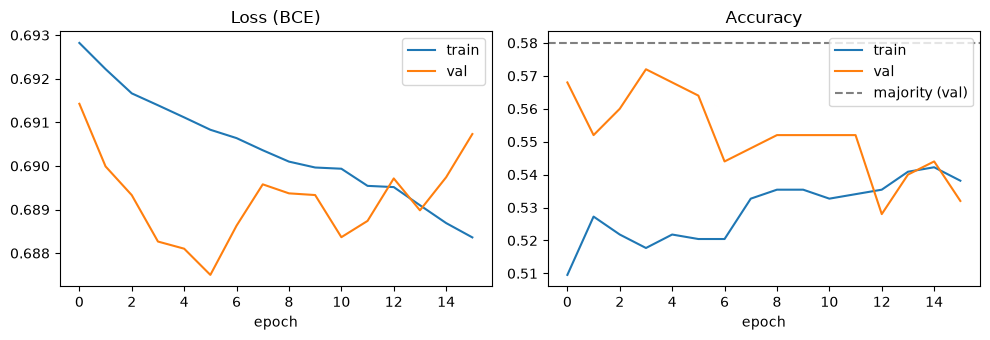

In [107]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["val_loss"], label="val")
ax[0].set_title("Loss (BCE)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist["train_acc"], label="train"); ax[1].plot(hist["val_acc"], label="val")
ax[1].axhline(y_va.mean(), ls="--", c="gray", label="majority (val)")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/lstm_price_curves.png", dpi=200); plt.show()

## Four versions, 5 seeds each
The same LSTM is trained with each feature set. A signal counts as helpful only if its gain over the price-only version is larger than the variation across seeds.

In [108]:
versions = {"price": PRICE, "price+news": PRICE + NEWS, "price+kalshi": PRICE + KALSHI, "all": ALL}

rows = []
for name, cols in versions.items():
    Xtr, ytr = make_windows(cols, train_mask)
    Xva, yva = make_windows(cols, val_mask)
    Xte, yte = make_windows(cols, test_mask)
    tl, vl, sl = loader(Xtr, ytr, True), loader(Xva, yva, False), loader(Xte, yte, False)

    for seed in range(5):
        torch.manual_seed(seed)
        m = LSTMClassifier(n_features=len(cols), hidden=32)
        train_lstm(m, tl, vl)
        rows.append({"version": name, "seed": seed, "val_acc": accuracy(m, vl),
                     "test_acc": accuracy(m, sl), "test_up_share": up_share(m, Xte)})

results = pd.DataFrame(rows)
summary = results.groupby("version")[["val_acc", "test_acc", "test_up_share"]].agg(["mean", "std"]).round(3)
summary = summary.loc[list(versions)]          # keep the order price, +news, +kalshi, all
print(summary)

results.to_csv("results/versions_all_seeds.csv", index=False)
summary.to_csv("results/versions_summary.csv")

             val_acc        test_acc        test_up_share       
                mean    std     mean    std          mean    std
version                                                         
price          0.572  0.011    0.511  0.005         0.996  0.006
price+news     0.571  0.011    0.510  0.008         0.960  0.056
price+kalshi   0.572  0.007    0.520  0.006         0.953  0.049
all            0.574  0.004    0.532  0.015         0.926  0.051
